# NB4 · Complex adaptation II: fine-tuning a generative LLM (decoder) for question answering

**Lecture:** 3 · Complex adaptation (fine-tuning decoders)  **Time:** ≈ 45–60 min (≈ 20–30 min of it is training)  **Hardware:** Colab T4 (16 GB) or better

**Task.** Given a *context passage* and a *question*, answer with the **shortest exact phrase** from the context — or say **“Not in the context.”** if the passage does not contain the answer. This is the grounded-QA pattern behind most RAG systems in business and science.

**Data.** [SQuAD v2](https://huggingface.co/datasets/rajpurkar/squad_v2): Wikipedia passages with answerable *and* unanswerable questions.

**What you will do**
1. **Check the data** (answers really in the context, leakage, answer lengths) and turn raw QA records into **conversational prompt–completion** examples.
2. Measure the **base model** (exact match, F1, abstention).
3. Fine-tune with **QLoRA** (4-bit base + LoRA adapters) using TRL’s `SFTTrainer`.
4. Re-evaluate, look at what changed, and **save the adapter**; then combine it with the **retrieved passages from NB2** (RAG + fine-tuning).
5. *(Stretch)* **Classic full fine-tuning** of a smaller model for comparison; the **same LoRA recipe for sentiment** (a generative classifier vs NB2’s encoder); merge the adapter; swap in GaMS / Gemma / Llama; use your own data.

## 0 · Setup

In [1]:
%pip install -q -U transformers datasets accelerate peft trl bitsandbytes pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [3]:
import os, re, string, collections, time, random, json
import numpy as np, pandas as pd, torch
from datasets import load_dataset, Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

set_seed(42)
BF16 = torch.cuda.get_device_capability()[0] >= 8   # native bf16 needs Ampere+; False on T4
DTYPE = torch.bfloat16 if BF16 else torch.float16
print(torch.cuda.get_device_name(0), "| bf16:", BF16)

Tesla T4 | bf16: False


## 1 · Model

Default: `Qwen/Qwen2.5-1.5B-Instruct` (open, no licence gate, fits a T4 comfortably).
Alternatives (change one line):
* `google/gemma-3-1b-it` — gated: accept the licence on Hugging Face and run `from huggingface_hub import login; login()`
* `meta-llama/Llama-3.2-1B-Instruct` — gated, same procedure
* `cjvt/GaMS-1B-Chat` — Slovenian (check the exact model ID on [hf.co/cjvt](https://huggingface.co/cjvt)); bigger GaMS models need QLoRA on a ≥ 24 GB GPU

In [4]:
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

tok = AutoTokenizer.from_pretrained(MODEL)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"                        # for batched generation

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
model = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb, device_map="auto", dtype=DTYPE)
print(f"GPU memory after loading: {torch.cuda.memory_allocated()/1e9:.2f} GB")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

GPU memory after loading: 1.15 GB


## 2 · Data preparation

* **Train:** a random sample of SQuAD v2 *train*.
* **Validation / test:** SQuAD v2 *validation*, split **by article title** so no article appears in both (grouped split — no leakage).
* Unanswerable questions get the target `Not in the context.`

In [5]:
raw = load_dataset("rajpurkar/squad_v2")
N_TRAIN, N_VAL, N_TEST = 3000, 200, 400          # increase N_TRAIN if you have time / a bigger GPU
ABSTAIN = "Not in the context."

def split_by_title(d, test_frac=0.5, seed=0):
    titles = sorted(set(d["title"]))
    random.Random(seed).shuffle(titles)
    test_titles = set(titles[: int(len(titles) * test_frac)])
    is_test = [t in test_titles for t in d["title"]]
    idx_test = [i for i, x in enumerate(is_test) if x]
    idx_val = [i for i, x in enumerate(is_test) if not x]
    return d.select(idx_val), d.select(idx_test)

val_raw, test_raw = split_by_title(raw["validation"])
train_raw = raw["train"].shuffle(seed=42).select(range(N_TRAIN))
val_raw = val_raw.shuffle(seed=42).select(range(N_VAL))
test_raw = test_raw.shuffle(seed=42).select(range(N_TEST))
assert not set(val_raw["title"]) & set(test_raw["title"])

frac_unans = np.mean([len(a["text"]) == 0 for a in train_raw["answers"]])
print(f"train {len(train_raw)}, val {len(val_raw)}, test {len(test_raw)}; unanswerable in train: {frac_unans:.0%}")
test_raw.to_json("qa_test.jsonl")

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

train 3000, val 200, test 400; unanswerable in train: 35%


Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

437885

### Conversational prompt–completion format

The dataset stores **messages**, not a model-specific string. TRL applies the model’s chat template and computes the loss **only on the completion**.

In [7]:
SYSTEM = ("You answer questions using only the given context. Reply with the shortest exact phrase "
          f"from the context that answers the question. If the context does not contain the answer, reply exactly: {ABSTAIN}")

def prompt_messages(context, question):
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}]

def gold_answers(ex):
    return ex["answers"]["text"] if len(ex["answers"]["text"]) else [ABSTAIN]

def to_sft(ex):
    return {"prompt": prompt_messages(ex["context"], ex["question"]),
            "completion": [{"role": "assistant", "content": gold_answers(ex)[0]}]}

train_ds = train_raw.map(to_sft, remove_columns=train_raw.column_names)
val_ds = val_raw.map(to_sft, remove_columns=val_raw.column_names)
print(json.dumps(train_ds[0], indent=1, ensure_ascii=False)[:1200])

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

{
 "prompt": [
  {
   "role": "system",
   "content": "You answer questions using only the given context. Reply with the shortest exact phrase from the context that answers the question. If the context does not contain the answer, reply exactly: Not in the context."
  },
  {
   "role": "user",
   "content": "Context:\nThe Roman Catholic Church canon law also includes the main five rites (groups) of churches which are in full union with the Roman Catholic Church and the Supreme Pontiff:\n\nQuestion: What term characterizes the intersection of the rites with the Roman Catholic Church?"
  }
 ],
 "completion": [
  {
   "role": "assistant",
   "content": "full union"
  }
 ]
}


In [8]:
# What the model actually sees (the chat template applied):
print(tok.apply_chat_template(train_ds[0]["prompt"] + train_ds[0]["completion"], tokenize=False))
lens = [len(tok.apply_chat_template(p + c, tokenize=True, return_dict=True)["input_ids"]) for p, c in zip(train_ds["prompt"][:500], train_ds["completion"][:500])]
print("token length percentiles 50/95/99:", np.percentile(lens, [50, 95, 99]))

<|im_start|>system
You answer questions using only the given context. Reply with the shortest exact phrase from the context that answers the question. If the context does not contain the answer, reply exactly: Not in the context.<|im_end|>
<|im_start|>user
Context:
The Roman Catholic Church canon law also includes the main five rites (groups) of churches which are in full union with the Roman Catholic Church and the Supreme Pontiff:

Question: What term characterizes the intersection of the rites with the Roman Catholic Church?<|im_end|>
<|im_start|>assistant
full union<|im_end|>

token length percentiles 50/95/99: [228.   378.05 480.17]


## 3 · Evaluation functions

SQuAD-style **exact match** and **token F1** (after lower-casing and removing punctuation and articles), max over all gold answers. We also report **abstention** precision/recall on unanswerable questions.

In [9]:
def normalize(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def f1(pred, gold):
    p, g = normalize(pred).split(), normalize(gold).split()
    common = collections.Counter(p) & collections.Counter(g)
    same = sum(common.values())
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(g)
    return 2 * prec * rec / (prec + rec)

def is_abstain(s):
    return normalize(s).startswith(normalize(ABSTAIN))

def evaluate_qa(preds, examples):
    em, f, rows = [], [], []
    tp = fp = fn = 0
    for pred, ex in zip(preds, examples):
        golds = gold_answers(ex)
        unans = golds == [ABSTAIN]
        e = max(float(normalize(pred) == normalize(g)) for g in golds)
        if unans:
            e = float(is_abstain(pred))
        ff = e if unans else max(f1(pred, g) for g in golds)
        em.append(e); f.append(ff)
        tp += unans and is_abstain(pred); fp += (not unans) and is_abstain(pred); fn += unans and not is_abstain(pred)
        rows.append({"question": ex["question"], "gold": golds[0], "pred": pred, "em": e, "unanswerable": unans})
    res = {"exact_match": np.mean(em), "f1": np.mean(f),
           "abstain_precision": tp / max(tp + fp, 1), "abstain_recall": tp / max(tp + fn, 1),
           "mean_answer_words": np.mean([len(r["pred"].split()) for r in rows])}
    return {k: round(float(v), 3) for k, v in res.items()}, pd.DataFrame(rows)

### Batched generation with Hugging Face

Simple and good enough for a few hundred examples. (NB4 shows the much faster vLLM way.)

In [10]:
@torch.no_grad()
def generate_answers(model, examples, batch_size=16, max_new_tokens=32, tokenizer=None):
    tok_ = tokenizer or tok
    tok_.padding_side = "left"
    model.eval()
    outs = []
    for i in range(0, len(examples), batch_size):
        batch = examples[i : i + batch_size]
        texts = [tok_.apply_chat_template(prompt_messages(c, q), tokenize=False, add_generation_prompt=True)
                 for c, q in zip(batch["context"], batch["question"])]
        enc = tok_(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok_.pad_token_id, use_cache=True)
        outs += tok_.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

t0 = time.time()
base_preds = generate_answers(model, test_raw)
print(f"{len(test_raw)} answers in {time.time()-t0:.0f} s")
base_scores, base_df = evaluate_qa(base_preds, test_raw)
base_scores

400 answers in 75 s


{'exact_match': 0.487,
 'f1': 0.556,
 'abstain_precision': 0.895,
 'abstain_recall': 0.28,
 'mean_answer_words': 4.397}

In [ ]:
pd.set_option("display.max_colwidth", 120)
base_df.sample(10, random_state=1)

**What do you notice?** Typical issues of the base model: answers that are full sentences instead of short phrases (hurts exact match), and answering anyway when the context does not contain the answer.

## 4 · QLoRA fine-tuning

In [12]:
peft_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                      target_modules="all-linear", task_type="CAUSAL_LM")

cfg = SFTConfig(
    output_dir="out/qa-lora",
    num_train_epochs=1,                  # 1 epoch of 3k examples ≈ 190 steps
    learning_rate=2e-4, lr_scheduler_type="cosine",
    per_device_train_batch_size=8, gradient_accumulation_steps=2,
    per_device_eval_batch_size=8,
    max_length=768,
    gradient_checkpointing=True,
    bf16=BF16, fp16=not BF16,
    eval_strategy="steps", eval_steps=50, logging_steps=10,
    save_strategy="no", report_to="none", seed=42)

trainer = SFTTrainer(model=model, args=cfg, processing_class=tok,
                     train_dataset=train_ds, eval_dataset=val_ds, peft_config=peft_cfg)
if not BF16:
    # TRL stores QLoRA adapter weights in bf16, which T4-class GPUs lack natively.
    # Keep the (tiny) adapters in fp32 instead; fp16 autocast still does the heavy matmuls.
    for n, p in trainer.model.named_parameters():
        if p.requires_grad:
            p.data = p.data.float()
trainer.model.print_trainable_parameters()

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Tokenizing train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


In [14]:
t0 = time.time()
trainer.train()
print(f"training took {(time.time()-t0)/60:.1f} min; peak GPU memory {torch.cuda.max_memory_allocated()/1e9:.1f} GB")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.256004,0.221136,0.238789,0.937373,204315.000000
100,0.242225,0.172626,0.226227,0.948277,393167.000000
150,0.235148,0.162977,0.188937,0.948463,583541.000000
188,0.224829,0.162056,0.201142,0.948598,728972.000000


training took 13.7 min; peak GPU memory 3.1 GB


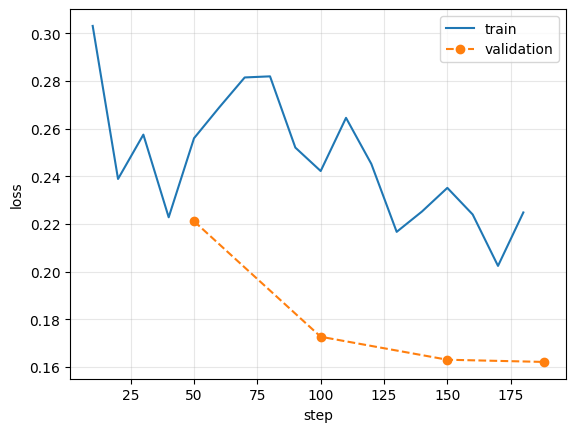

In [15]:
import matplotlib.pyplot as plt
log = pd.DataFrame(trainer.state.log_history)
plt.plot(log.dropna(subset=["loss"]).step, log.dropna(subset=["loss"]).loss, label="train")
plt.plot(log.dropna(subset=["eval_loss"]).step, log.dropna(subset=["eval_loss"]).eval_loss, "o--", label="validation")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 5 · Evaluate the fine-tuned model

In [16]:
tok.padding_side = "left"
t0 = time.time()
lora_preds = generate_answers(trainer.model, test_raw)
print(f"{len(test_raw)} answers in {time.time()-t0:.0f} s")
lora_scores, lora_df = evaluate_qa(lora_preds, test_raw)
pd.DataFrame({"base": base_scores, "QLoRA": lora_scores})

400 answers in 96 s


,base,QLoRA
exact_match,0.487,0.748
f1,0.556,0.775
abstain_precision,0.895,0.770
abstain_recall,0.280,0.808
mean_answer_words,4.397,3.578


In [17]:
cmp = pd.DataFrame({"question": test_raw["question"], "gold": [gold_answers(e)[0] for e in test_raw],
                    "base": base_preds, "lora": lora_preds})
print("Fixed by LoRA:")
display(cmp[(base_df.em == 0) & (lora_df.em == 1)].head(8))
print("Broken by LoRA:")
display(cmp[(base_df.em == 1) & (lora_df.em == 0)].head(8))

Fixed by LoRA:


,question,gold,base,lora
6,What kind of Sunni muslim monarchy is is Iran ...,Not in the context.,near absolutist monarchy,Not in the context.
8,Why was OC-12c considered a substantial engine...,Not in the context.,"By 1998, the vBNS had grown to connect more th...",Not in the context.
11,What French city was Jacques Lefevre from?,Not in the context.,Paris,Not in the context.
12,What happened when new oil was withdrawn from ...,Not in the context.,greater scarcity,Not in the context.
24,What city did the Grand Canal never reach dur...,Not in the context.,Beijing,Not in the context.
25,What did DECnet Phase I become?,Not in the context.,a seven-layer OSI-compliant networking protocol,Not in the context.
32,What Chinese era name did Kublai reject?,Not in the context.,Zhongtong,Not in the context.
33,Policies which reduce the inequality associate...,Not in the context.,economic,Not in the context.


Broken by LoRA:


,question,gold,base,lora
9,What type of amendments might members opposed ...,wrecking,wrecking amendments,Not in the context.
14,What were the years two Regulations that confl...,1964 and 1968,1964 and 1968,Not in the context.
23,What persons were not allowed to settle in New...,non-Catholics,non-Catholics,Not in the context.
38,How is oxygen ranked as abundant in the universe?,third,third,third most abundant chemical element
41,Who became the King of the Canary Islands?,Bethencourt,Bethencourt,Not in the context.
56,How many days does the Parliament have to nomi...,28,28 days,Not in the context.
64,How far from the Yard is the Quad located?,half a mile northwest of the Yard,half a mile northwest of the Yard,half a mile northwest
70,What Harvard Alumni was the Palestine Prime Mi...,Benjamin Netanyahu,Benjamin Netanyahu,Not in the context.


✍️ **Discuss.** How much of the gain is *format* (shorter answers) and how much is *substance*? Compare F1 vs exact match, and `mean_answer_words`. Are the “broken by LoRA” cases real errors or harmless paraphrases?

## 6 · Save the adapter

In [18]:
trainer.save_model("out/qa-lora/adapter")        # adapter weights + config
tok.save_pretrained("out/qa-lora/adapter")
!du -sh out/qa-lora/adapter
pd.DataFrame({"base": base_scores, "QLoRA": lora_scores}).to_csv("nb3_results.csv")

82M	out/qa-lora/adapter


Exercise: can you make the adapter accept dynamically retrieved context instead?

## 8 · Stretch: merge the adapter into a 16-bit base
Merge into a base loaded in 16-bit, never into the 4-bit one. Restart the runtime first if memory is tight.

In [ ]:
# from peft import AutoPeftModelForCausalLM
# merged = AutoPeftModelForCausalLM.from_pretrained("out/qa-lora/adapter", dtype=DTYPE, device_map="auto").merge_and_unload()
# merged.save_pretrained("out/qa-merged"); tok.save_pretrained("out/qa-merged")

## 9b · Stretch: the same LoRA recipe for sentiment (a generative classifier)

Nothing in the SFT recipe is QA-specific: a **label is just a very short completion**. Here we LoRA-tune the 1.5B model on Rotten Tomatoes and compare it with the encoder you fine-tuned in NB3 (discriminative) and with zero-shot prompting.

In [20]:
import gc
from sklearn.metrics import f1_score
for v in ["small", "full_trainer", "trainer", "model"]:
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

reviews = load_dataset("cornell-movie-review-data/rotten_tomatoes")
LABELS = ["negative", "positive"]
SENT_SYSTEM = ("You label movie reviews. positive = the reviewer's overall opinion is favourable, "
               "negative = unfavourable. Answer with exactly one word: positive or negative.")

def sent_prompt(text):
    return [{"role": "system", "content": SENT_SYSTEM}, {"role": "user", "content": text}]

def sent_sft(ex):
    return {"prompt": sent_prompt(ex["text"]),
            "completion": [{"role": "assistant", "content": LABELS[ex["label"]]}]}

sent_train = reviews["train"].shuffle(seed=0).select(range(2000)).map(sent_sft, remove_columns=["text", "label"])
sent_test = reviews["test"].shuffle(seed=42).select(range(400))

model = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb, device_map="auto", dtype=DTYPE)
tok.padding_side = "left"

@torch.no_grad()
def classify(m, texts, bs=32):
    m.eval(); out = []
    for i in range(0, len(texts), bs):
        prompts = [tok.apply_chat_template(sent_prompt(t), tokenize=False, add_generation_prompt=True) for t in texts[i:i+bs]]
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(m.device)
        gen = m.generate(**enc, max_new_tokens=3, do_sample=False, pad_token_id=tok.pad_token_id, use_cache=True)
        for o in tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True):
            o = o.strip().lower()
            out.append(1 if o.startswith("pos") else 0 if o.startswith("neg") else -1)   # -1 = invalid
    return np.array(out)

y_sent = np.array(sent_test["label"])
zs = classify(model, sent_test["text"])
print(f"zero-shot macro-F1 {f1_score(y_sent, zs, average='macro'):.3f}, invalid {np.mean(zs == -1):.1%}")

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

... (3 outputs left out)

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

zero-shot macro-F1 0.882, invalid 0.0%


In [21]:
sent_cfg = SFTConfig(output_dir="out/sent-lora", num_train_epochs=1, learning_rate=2e-4,
                     per_device_train_batch_size=16, gradient_accumulation_steps=1, max_length=256,
                     gradient_checkpointing=True, bf16=BF16, fp16=not BF16,
                     logging_steps=20, save_strategy="no", report_to="none", seed=42)
sent_trainer = SFTTrainer(model=model, args=sent_cfg, processing_class=tok,
                          train_dataset=sent_train, peft_config=peft_cfg)
if not BF16:
    for n, p in sent_trainer.model.named_parameters():
        if p.requires_grad: p.data = p.data.float()
sent_trainer.train()
sent_trainer.save_model("out/sent-lora")          # a second adapter for the same base model

ft = classify(sent_trainer.model, sent_test["text"])
print(f"LoRA macro-F1 {f1_score(y_sent, ft, average='macro'):.3f}, invalid {np.mean(ft == -1):.1%}")

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Step,Training Loss
20,0.244512
40,0.106963
60,0.059241
80,0.076588
100,0.077450
120,0.083104


LoRA macro-F1 0.907, invalid 0.0%
Compare with your NB3 encoder (fine-tuned row) — note NB3 used the full test set.


## 10 · Stretch: your own data, your own model

**Data.** Create a JSONL file with one object per line: `{"context": ..., "question": ..., "answer": ...}` (use `""` for unanswerable). Then:

In [ ]:
# mine = load_dataset("json", data_files="my_qa.jsonl")["train"]
# mine = mine.map(lambda ex: {"answers": {"text": [ex["answer"]] if ex["answer"] else [], "answer_start": []},
#                             "title": ex.get("doc_id", "doc")})
# ...split by document (as in section 2) and re-run from there.
#
# Model: set MODEL = "cjvt/GaMS-1B-Chat" (Slovenian) or "google/gemma-3-1b-it" and restart from section 1.
# Translate SYSTEM and ABSTAIN to the language of your data (e.g. ABSTAIN = "Ni v kontekstu.").